# Synthetic Augmentation Strategy Analysis
## SHROOM-visions — All Five Strategies vs Baseline

Compares all six strategies (S1a / S1b / S2 / S3 / S4 / S5) against the no-augmentation baseline.  
Where a `_v2` notebook exists, that version was used as the canonical run.

**Metrics:**
- **Span IoU** — overlap between predicted and gold hallucination spans
- **Spearman ρ** — rank correlation of per-character hallucination probabilities
- **Cat F1 (macro)** — macro-averaged F1 across the five hallucination categories

**Categories tracked:** invention · mischaracterization (lost to col-name collision) · OCR · miscounting · other

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from IPython.display import Image, display

plt.rcParams.update({'figure.dpi': 130, 'font.size': 10})
sns.set_theme(style='whitegrid')

BASE_DIR = Path('.')   # adjust if running from a different working directory
print('Ready.')

Ready.


In [2]:
# ── Strategy metadata ─────────────────────────────────────────────────────────
STRATEGIES = {
    'Baseline':   {'label': 'Baseline (no synth)',      'color': '#444444', 'folder': None},
    'S1a':        {'label': 'S1a Heuristic Inj. (v2)',  'color': '#e07b54', 'folder': 'ft_predictions_S1a_HeuristicInjection'},
    'S1b':        {'label': 'S1b LLM Injection',        'color': '#e0a854', 'folder': 'ft_predictions_S1b_LLMInjection'},
    'S2':         {'label': 'S2 Cross-Lingual (v2)',    'color': '#7fb1d3', 'folder': 'ft_predictions_S2_CrossLingualTransfer'},
    'S3':         {'label': 'S3 Back-Translation (v2)', 'color': '#5ba65b', 'folder': 'ft_predictions_S3_BackTranslation'},
    'S4':         {'label': 'S4 Agreement Upsamp.',     'color': '#c44bc4', 'folder': 'ft_predictions_S4_AgreementUpsampling'},
    'S5':         {'label': 'S5 Multi-LVLM Fusion (v2)','color': '#d4d443', 'folder': 'ft_predictions_S5_MultiLVLMFusion'},
}

# ── Hardcoded results (extracted from CSVs + S4 comparison file for baseline) ──
LANGS = ['EN', 'FR', 'IT', 'ZH', 'OVERALL']
METRICS = ['Span IoU', 'Spearman rho', 'Cat F1 (macro)']
CATS = ['F1(inve)', 'F1(misc)', 'F1(OCR)', 'F1(othe)']   # F1(misc) = miscounting (mischaracterization col overwritten)

raw = {
    'Baseline': {
        'EN':      [0.2493, 0.3085, 0.2718, None, None, None, None],
        'FR':      [0.3386, 0.3551, 0.3364, None, None, None, None],
        'IT':      [0.3271, 0.3797, 0.2992, None, None, None, None],
        'ZH':      [0.3257, 0.3565, 0.2671, None, None, None, None],
        'OVERALL': [0.3102, 0.3500, 0.2861, None, None, None, None],
    },
    'S1a': {
        'EN':      [0.2117, 0.2651, 0.2227, 0.2315, 0.3962, 0.0652, 0.1071],
        'FR':      [0.2731, 0.2991, 0.2308, 0.3333, 0.4286, 0.0714, 0.0000],
        'IT':      [0.2718, 0.3277, 0.2789, 0.4169, 0.3636, 0.1111, 0.1379],
        'ZH':      [0.2944, 0.3153, 0.2113, 0.3763, 0.3235, 0.0606, 0.1154],
        'OVERALL': [0.2627, 0.3018, 0.2300, 0.3171, 0.3478, 0.0529, 0.1366],
    },
    'S1b': {
        'EN':      [0.2063, 0.2709, 0.2635, 0.2900, 0.4074, 0.0759, 0.2182],
        'FR':      [0.2970, 0.3233, 0.2437, 0.3671, 0.4444, 0.0800, 0.0513],
        'IT':      [0.2911, 0.3425, 0.2304, 0.3725, 0.3908, 0.0000, 0.0370],
        'ZH':      [0.3076, 0.3370, 0.2509, 0.3940, 0.3562, 0.1538, 0.1500],
        'OVERALL': [0.2755, 0.3184, 0.2481, 0.3380, 0.3934, 0.0828, 0.1277],
    },
    'S2': {
        'EN':      [0.2367, 0.2753, 0.2601, 0.3507, 0.3704, 0.1026, 0.1887],
        'FR':      [0.2738, 0.2816, 0.2563, 0.3748, 0.4000, 0.0800, 0.1212],
        'IT':      [0.2938, 0.3169, 0.2760, 0.4545, 0.4138, 0.0588, 0.1509],
        'ZH':      [0.3177, 0.3479, 0.2392, 0.4348, 0.3567, 0.0000, 0.1538],
        'OVERALL': [0.2805, 0.3054, 0.2435, 0.3728, 0.3796, 0.0814, 0.1011],
    },
    'S3': {
        'EN':      [0.2020, 0.2377, 0.2593, 0.3433, 0.4466, 0.1111, 0.1176],
        'FR':      [0.2939, 0.3043, 0.2688, 0.4277, 0.4000, 0.0667, 0.1111],
        'IT':      [0.3123, 0.3617, 0.2903, 0.4434, 0.4444, 0.0741, 0.1600],
        'ZH':      [0.2901, 0.3187, 0.2215, 0.4390, 0.3714, 0.0000, 0.1579],
        'OVERALL': [0.2746, 0.3056, 0.2564, 0.3808, 0.4019, 0.0870, 0.1257],
    },
    'S4': {
        'EN':      [0.2717, 0.2982, 0.2695, 0.3716, 0.3361, 0.2022, 0.0769],
        'FR':      [0.3368, 0.3482, 0.3001, 0.4786, 0.5111, 0.0000, 0.1176],
        'IT':      [0.3464, 0.3842, 0.3560, 0.4609, 0.4000, 0.2941, 0.2182],
        'ZH':      [0.3561, 0.3700, 0.2879, 0.4094, 0.4000, 0.1455, 0.2051],
        'OVERALL': [0.3278, 0.3501, 0.3096, 0.4280, 0.4093, 0.2029, 0.1444],
    },
    'S5': {
        'EN':      [0.2323, 0.2854, 0.2274, 0.3096, 0.3462, 0.0270, 0.1481],
        'FR':      [0.2975, 0.3084, 0.3107, 0.4547, 0.5060, 0.1250, 0.1081],
        'IT':      [0.2978, 0.3346, 0.2591, 0.4494, 0.3596, 0.0000, 0.1200],
        'ZH':      [0.3107, 0.3406, 0.2359, 0.4354, 0.3194, 0.0000, 0.1463],
        'OVERALL': [0.2846, 0.3172, 0.2493, 0.3996, 0.3667, 0.0380, 0.1209],
    },
}

COLS = METRICS + CATS
dfs = {}
for strat, lang_dict in raw.items():
    rows = []
    for lang in LANGS:
        rows.append([lang] + lang_dict[lang])
    dfs[strat] = pd.DataFrame(rows, columns=['Language'] + COLS).set_index('Language')

print('Data loaded.')
print('\nBaseline OVERALL:', dfs['Baseline'].loc['OVERALL', METRICS].to_dict())

Data loaded.

Baseline OVERALL: {'Span IoU': 0.3102, 'Spearman rho': 0.35, 'Cat F1 (macro)': 0.2861}


---
## 1. Overall Rankings
Which strategy is best for each metric? Green = beats baseline, red = below.

In [3]:
baseline_overall = dfs['Baseline'].loc['OVERALL']

rank_rows = []
for s in STRATEGIES:
    row = {'Strategy': STRATEGIES[s]['label']}
    for m in METRICS:
        val = dfs[s].loc['OVERALL', m]
        delta = val - baseline_overall[m] if s != 'Baseline' else 0.0
        row[m] = val
        row[f'Δ {m}'] = delta
    rank_rows.append(row)

rank_df = pd.DataFrame(rank_rows)

def color_delta(val):
    if pd.isna(val) or val == 0: return ''
    return 'background-color: #c6efce; color: #276221' if val > 0 else 'background-color: #ffc7ce; color: #9c0006'

delta_cols = [c for c in rank_df.columns if c.startswith('Δ')]
display(
    rank_df.style
    .format({m: '{:.4f}' for m in METRICS} | {d: '{:+.4f}' for d in delta_cols})
    .applymap(color_delta, subset=delta_cols)
    .set_caption('OVERALL metrics — all strategies vs baseline')
    .hide(axis='index')
)
print('\n★ Best per metric:')
for m in METRICS:
    best_idx = rank_df[m].idxmax()
    print(f'  {m}: {rank_df.loc[best_idx, "Strategy"]}  ({rank_df.loc[best_idx, m]:.4f})')

C:\Users\ROG\AppData\Local\Temp\ipykernel_18848\1125926351.py:21: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  rank_df.style


Strategy,Span IoU,Δ Span IoU,Spearman rho,Δ Spearman rho,Cat F1 (macro),Δ Cat F1 (macro)
Baseline (no synth),0.3102,+0.0000,0.3500,+0.0000,0.2861,+0.0000
S1a Heuristic Inj. (v2),0.2627,-0.0475,0.3018,-0.0482,0.2300,-0.0561
S1b LLM Injection,0.2755,-0.0347,0.3184,-0.0316,0.2481,-0.0380
S2 Cross-Lingual (v2),0.2805,-0.0297,0.3054,-0.0446,0.2435,-0.0426
S3 Back-Translation (v2),0.2746,-0.0356,0.3056,-0.0444,0.2564,-0.0297
S4 Agreement Upsamp.,0.3278,+0.0176,0.3501,+0.0001,0.3096,+0.0235
S5 Multi-LVLM Fusion (v2),0.2846,-0.0256,0.3172,-0.0328,0.2493,-0.0368



★ Best per metric:
  Span IoU: S4 Agreement Upsamp.  (0.3278)
  Spearman rho: S4 Agreement Upsamp.  (0.3501)
  Cat F1 (macro): S4 Agreement Upsamp.  (0.3096)


---
## 2. Metric Comparison vs Baseline

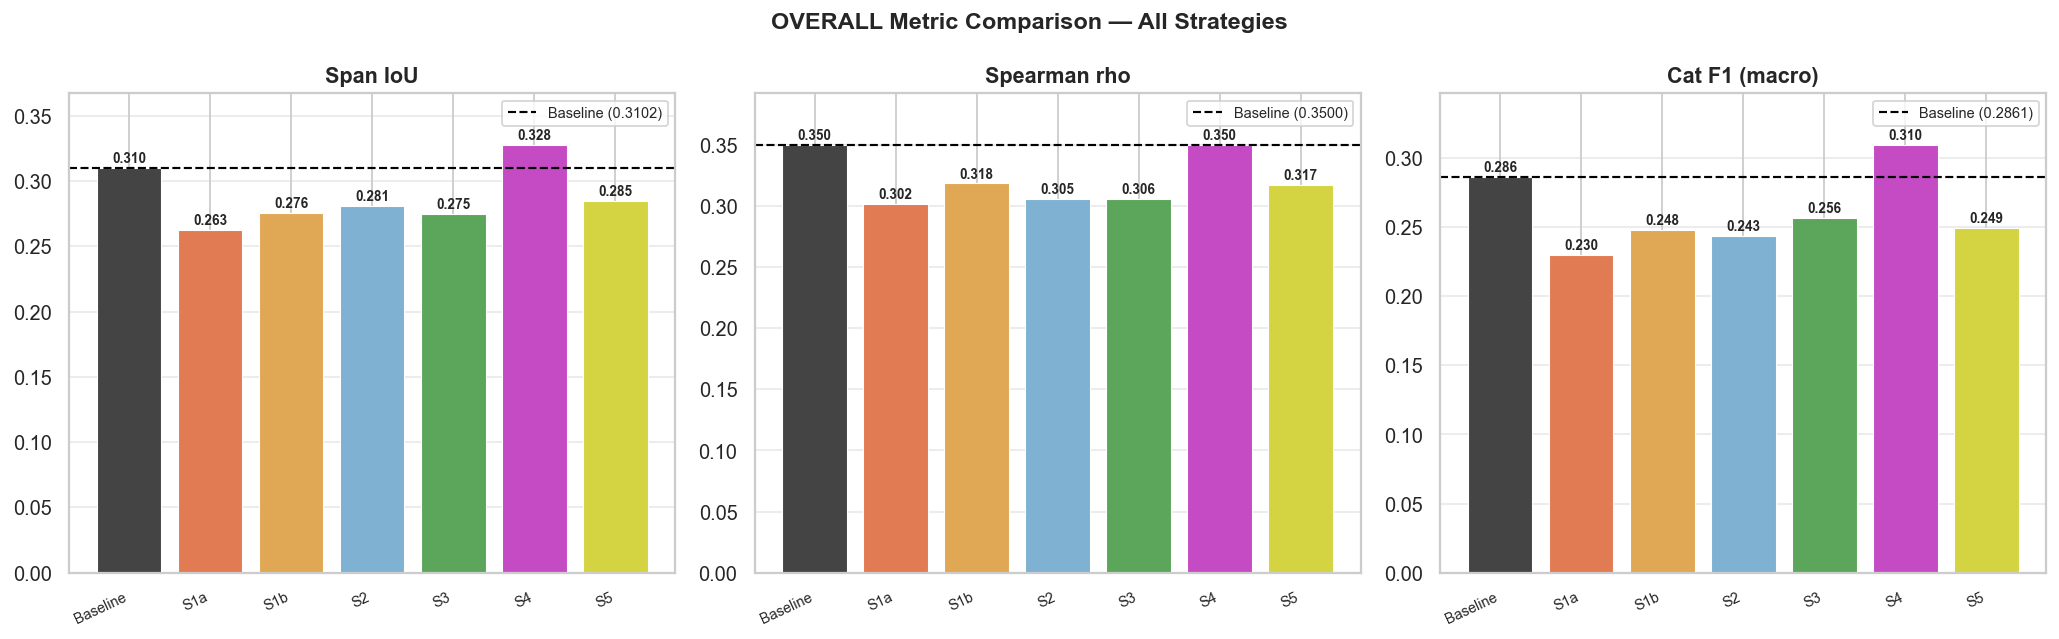

In [4]:
strat_keys = list(STRATEGIES.keys())
labels = [STRATEGIES[s]['label'] for s in strat_keys]
colors = [STRATEGIES[s]['color'] for s in strat_keys]
x = np.arange(len(strat_keys))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, METRICS):
    vals = [dfs[s].loc['OVERALL', metric] for s in strat_keys]
    baseline_val = dfs['Baseline'].loc['OVERALL', metric]
    bars = ax.bar(x, vals, color=colors, edgecolor='white', linewidth=0.6)
    ax.axhline(baseline_val, color='black', linestyle='--', linewidth=1.2, label=f'Baseline ({baseline_val:.4f})')
    for xi, (bar, v) in enumerate(zip(bars, vals)):
        ax.text(xi, v + 0.002, f'{v:.3f}', ha='center', va='bottom', fontsize=7.5, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([s for s in strat_keys], rotation=25, ha='right', fontsize=8)
    ax.set_title(metric, fontweight='bold', fontsize=12)
    ax.set_ylim(0, max(vals) * 1.12)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.4)

plt.suptitle('OVERALL Metric Comparison — All Strategies', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('plots/analysis_overall_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 3. Delta vs Baseline — Per Language × Per Strategy
Green cells = improvement over baseline. Red = regression.

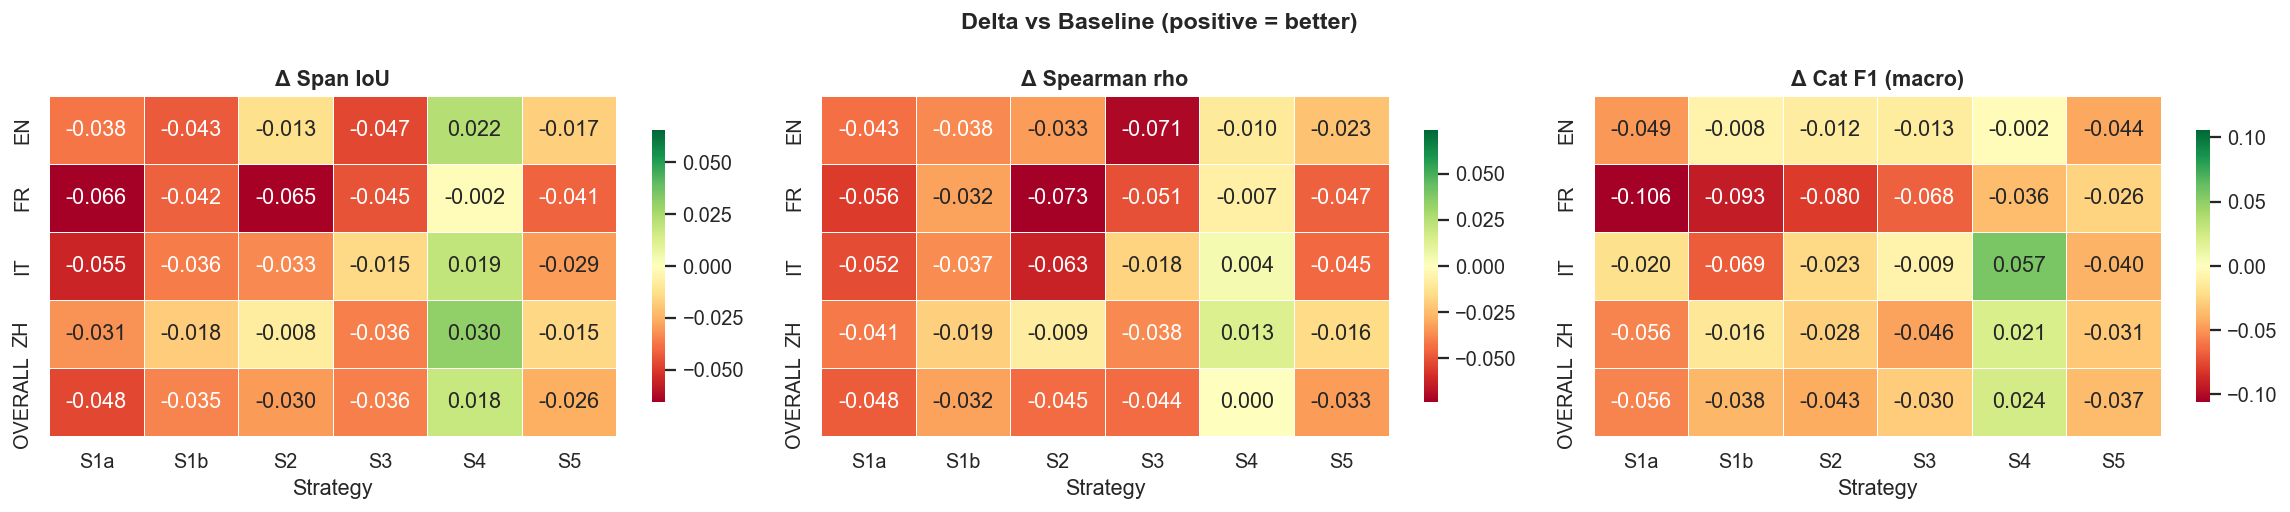

In [5]:
synth_keys = [s for s in strat_keys if s != 'Baseline']

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, METRICS):
    mat = []
    for lang in LANGS:
        row = []
        base_val = dfs['Baseline'].loc[lang, metric]
        for s in synth_keys:
            row.append(round(dfs[s].loc[lang, metric] - base_val, 4))
        mat.append(row)
    delta_df = pd.DataFrame(mat, index=LANGS, columns=[s for s in synth_keys])
    vmax = max(abs(delta_df.values.max()), abs(delta_df.values.min()))
    sns.heatmap(delta_df, ax=ax, cmap='RdYlGn', center=0, vmin=-vmax, vmax=vmax,
                annot=True, fmt='.3f', linewidths=0.5, linecolor='white',
                cbar_kws={'shrink': 0.8})
    ax.set_title(f'Δ {metric}', fontweight='bold')
    ax.set_xlabel('Strategy')
    ax.set_ylabel('')

plt.suptitle('Delta vs Baseline (positive = better)', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('plots/analysis_delta_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4. Per-Language Breakdown — Cat F1 (macro)

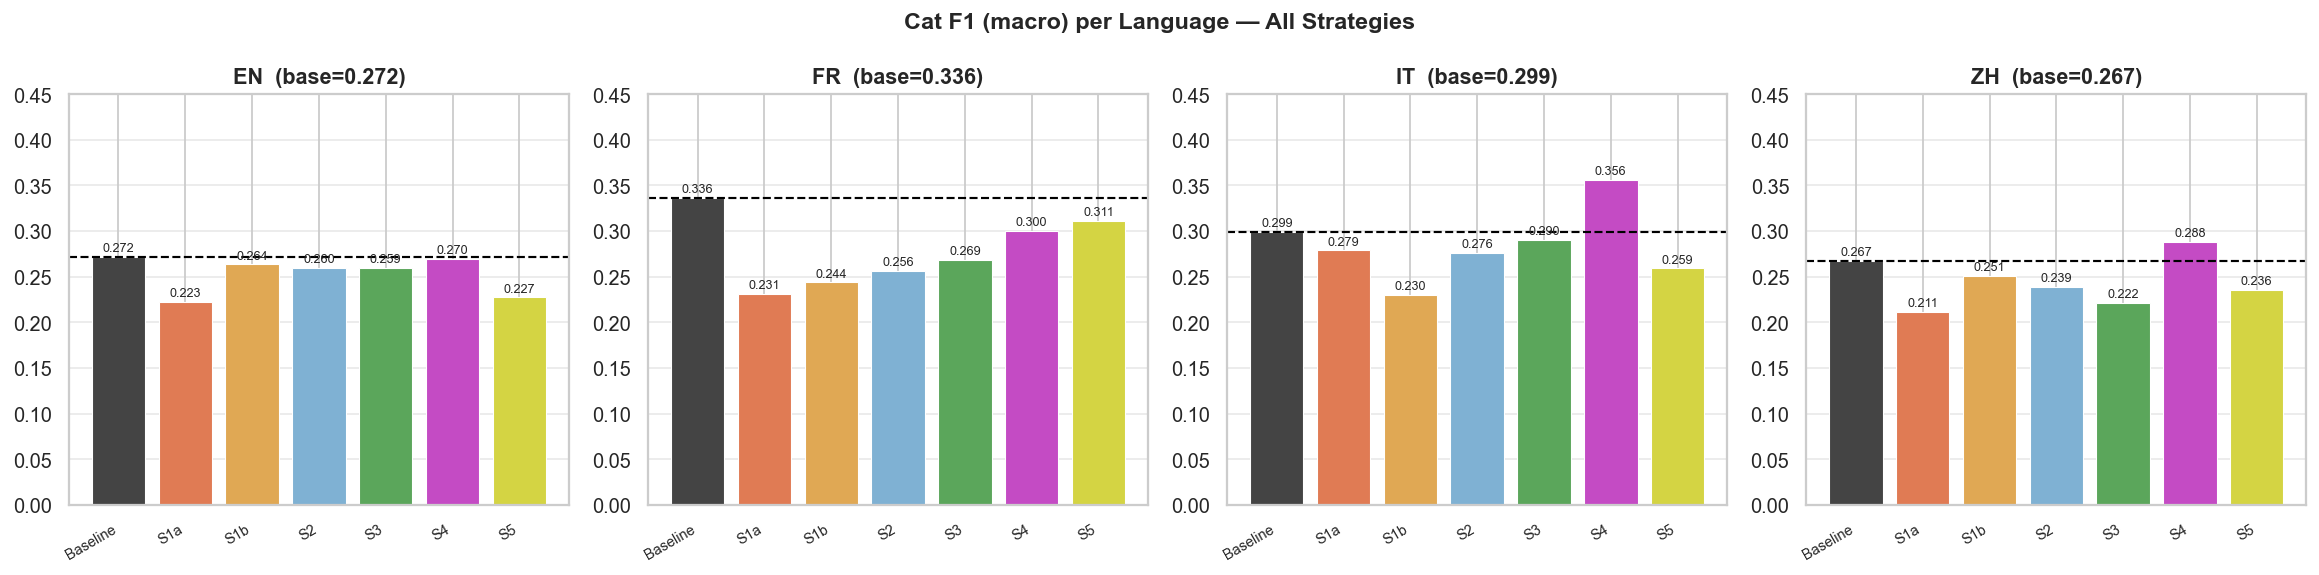

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=False)
lang_display = ['EN', 'FR', 'IT', 'ZH']

for ax, lang in zip(axes, lang_display):
    vals = [dfs[s].loc[lang, 'Cat F1 (macro)'] for s in strat_keys]
    base_val = dfs['Baseline'].loc[lang, 'Cat F1 (macro)']
    bars = ax.bar(range(len(strat_keys)), vals, color=colors, edgecolor='white', linewidth=0.6)
    ax.axhline(base_val, color='black', linestyle='--', linewidth=1.2)
    for xi, (bar, v) in enumerate(zip(bars, vals)):
        ax.text(xi, v + 0.003, f'{v:.3f}', ha='center', va='bottom', fontsize=7)
    ax.set_xticks(range(len(strat_keys)))
    ax.set_xticklabels(strat_keys, rotation=30, ha='right', fontsize=8)
    ax.set_title(f'{lang}  (base={base_val:.3f})', fontweight='bold')
    ax.set_ylim(0, 0.45)
    ax.grid(axis='y', alpha=0.4)

plt.suptitle('Cat F1 (macro) per Language — All Strategies', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('plots/analysis_perlang_catf1.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5. Per-Category F1 Heatmap (OVERALL)
> **Note:** F1(misc) = miscounting. Mischaracterization F1 was lost due to column-name collision in the results CSVs (both mischaracterization and miscounting truncate to 'misc'; miscounting overwrites).

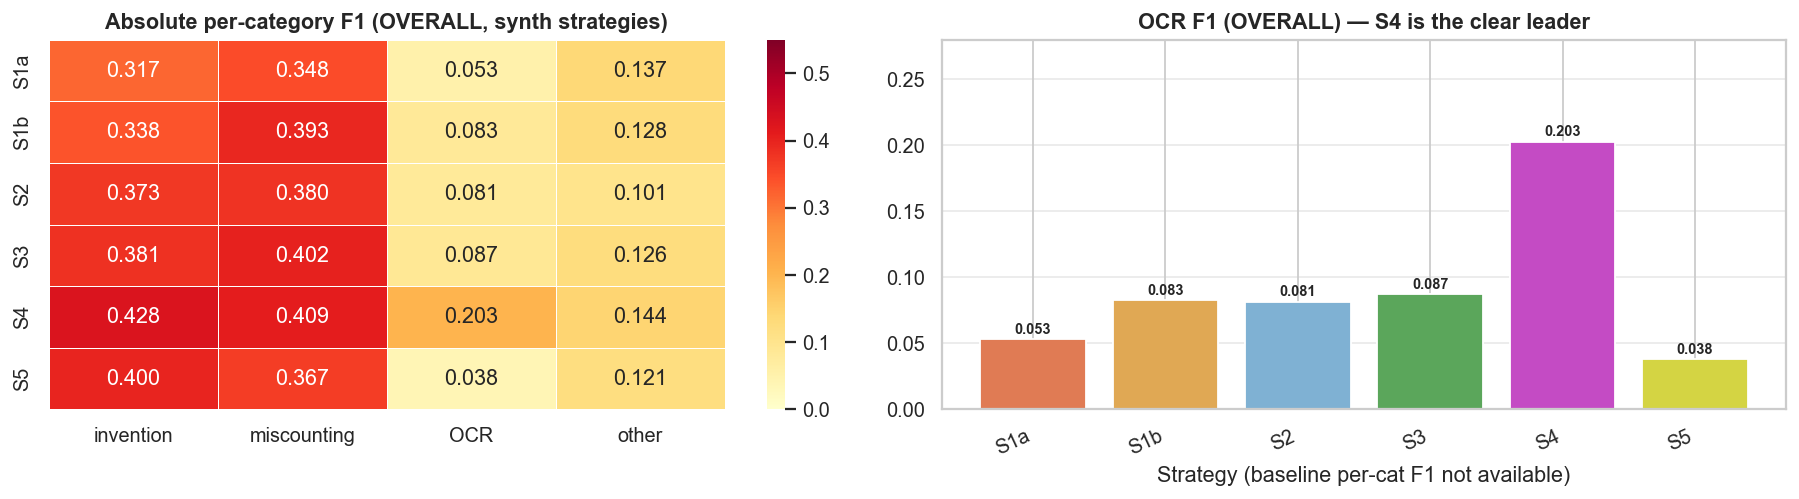


Category F1 rankings (OVERALL):
  invention           : S4  (0.428)
  miscounting         : S4  (0.409)
  OCR                 : S4  (0.203)
  other               : S4  (0.144)


In [12]:
cat_labels = {'F1(inve)': 'invention', 'F1(misc)': 'miscounting', 'F1(OCR)': 'OCR', 'F1(othe)': 'other'}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: heatmap — strategy × category (synth strategies only, baseline has no per-cat data)
mat_abs = []
for s in synth_keys:
    row = [dfs[s].loc['OVERALL', c] for c in CATS]
    mat_abs.append(row)
abs_df = pd.DataFrame(mat_abs, index=synth_keys, columns=[cat_labels[c] for c in CATS])

sns.heatmap(abs_df, ax=axes[0], cmap='YlOrRd', annot=True, fmt='.3f',
            linewidths=0.5, linecolor='white', vmin=0, vmax=0.55)
axes[0].set_title('Absolute per-category F1 (OVERALL, synth strategies)', fontweight='bold')

# Right: OCR F1 bar chart — synth only (baseline per-cat not available)
ocr_colors = [STRATEGIES[s]['color'] for s in synth_keys]
ocr_vals = [float(dfs[s].loc['OVERALL', 'F1(OCR)']) for s in synth_keys]
axes[1].bar(range(len(synth_keys)), ocr_vals, color=ocr_colors, edgecolor='white')
for xi, v in enumerate(ocr_vals):
    axes[1].text(xi, v + 0.002, f'{v:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
axes[1].set_title('OCR F1 (OVERALL) — S4 is the clear leader', fontweight='bold')
axes[1].set_xticks(range(len(synth_keys)))
axes[1].set_xticklabels(synth_keys, rotation=25, ha='right')
axes[1].set_ylim(0, 0.28)
axes[1].grid(axis='y', alpha=0.4)
axes[1].set_xlabel('Strategy (baseline per-cat F1 not available)')

plt.tight_layout()
plt.savefig('plots/analysis_percat_f1.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nCategory F1 rankings (OVERALL):')
for c, name in cat_labels.items():
    best = max(synth_keys, key=lambda s: dfs[s].loc['OVERALL', c])
    print(f'  {name:<20}: {best}  ({dfs[best].loc["OVERALL", c]:.3f})')

---
## 6. Strategy Radar — OVERALL Metrics (normalized)

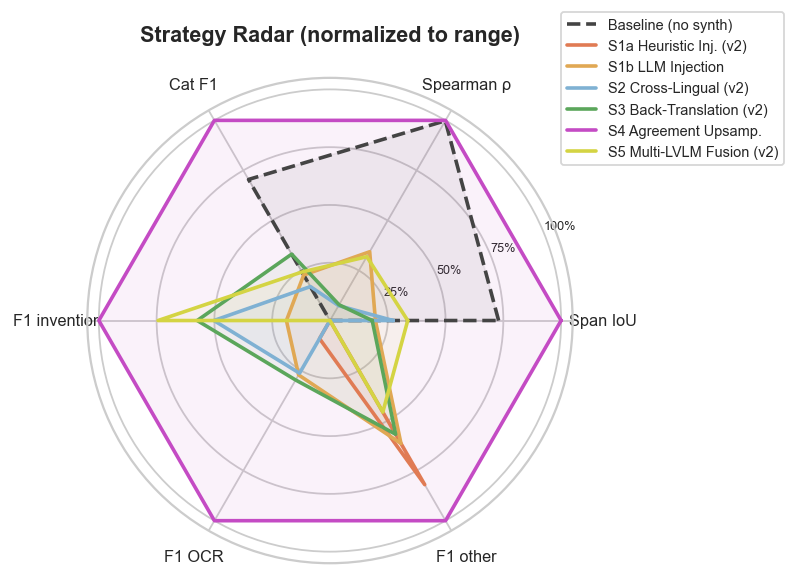

In [9]:
radar_cols = METRICS + ['F1(inve)', 'F1(OCR)', 'F1(othe)']
radar_labels = ['Span IoU', 'Spearman ρ', 'Cat F1', 'F1 invention', 'F1 OCR', 'F1 other']
N = len(radar_cols)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]  # close the polygon

# Normalize: each metric to [0,1] across all strategies
all_vals = {c: [dfs[s].loc['OVERALL', c] for s in strat_keys if dfs[s].loc['OVERALL', c] is not None] for c in radar_cols}
col_min = {c: min(v) for c, v in all_vals.items()}
col_max = {c: max(v) for c, v in all_vals.items()}

def normalize(s, c):
    v = dfs[s].loc['OVERALL', c]
    if v is None: return 0
    rng = col_max[c] - col_min[c]
    return (v - col_min[c]) / rng if rng > 0 else 0.5

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
for s in strat_keys:
    vals_norm = [normalize(s, c) for c in radar_cols]
    vals_norm += vals_norm[:1]
    ax.plot(angles, vals_norm, color=STRATEGIES[s]['color'], linewidth=2,
            linestyle='--' if s == 'Baseline' else '-', label=STRATEGIES[s]['label'])
    ax.fill(angles, vals_norm, color=STRATEGIES[s]['color'], alpha=0.07)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_labels, fontsize=9)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['25%', '50%', '75%', '100%'], fontsize=7)
ax.set_title('Strategy Radar (normalized to range)', fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.45, 1.15), fontsize=8)
plt.tight_layout()
plt.savefig('plots/analysis_radar.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 7. Training Loss Curves

── S1a Heuristic Inj. (v2) ──


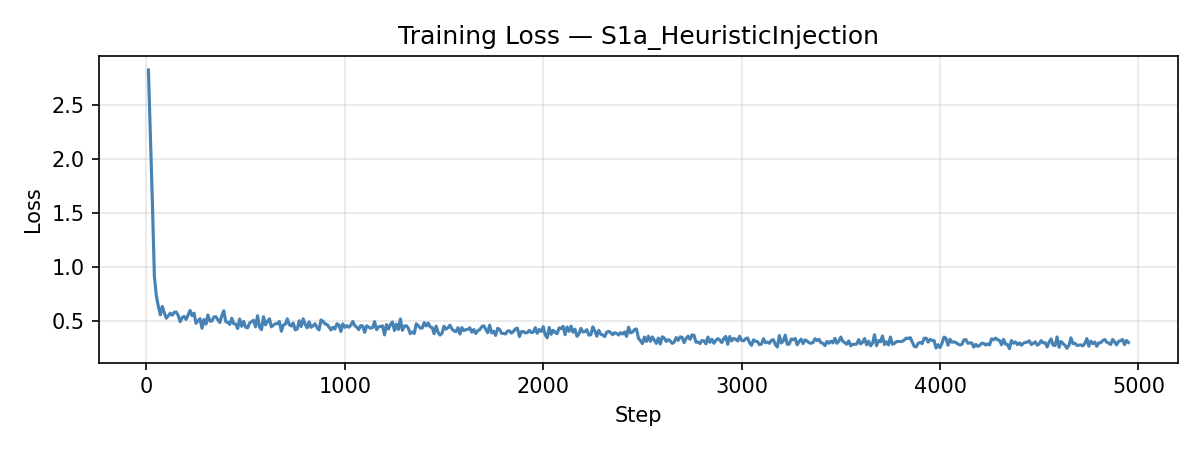

── S1b LLM Injection ──


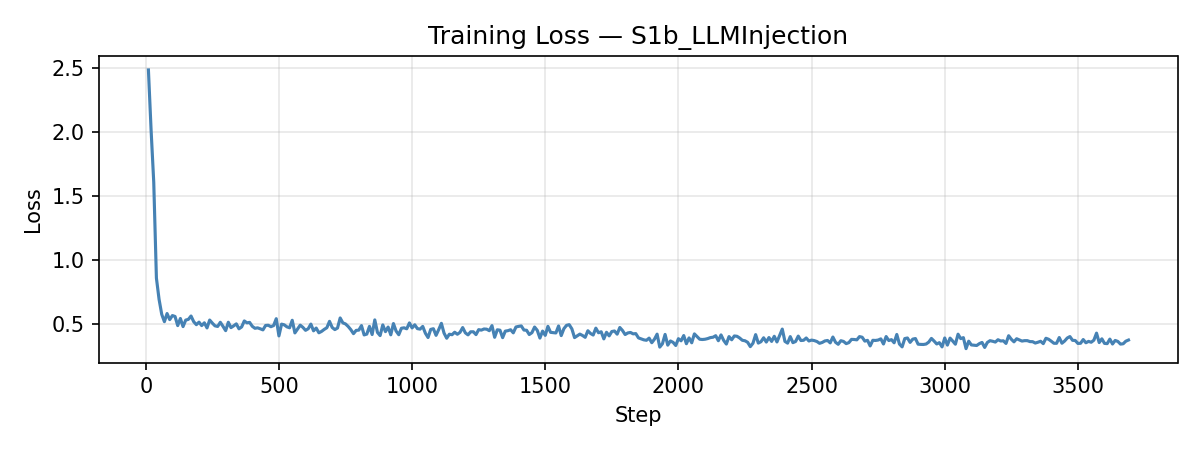

── S2 Cross-Lingual (v2) ──


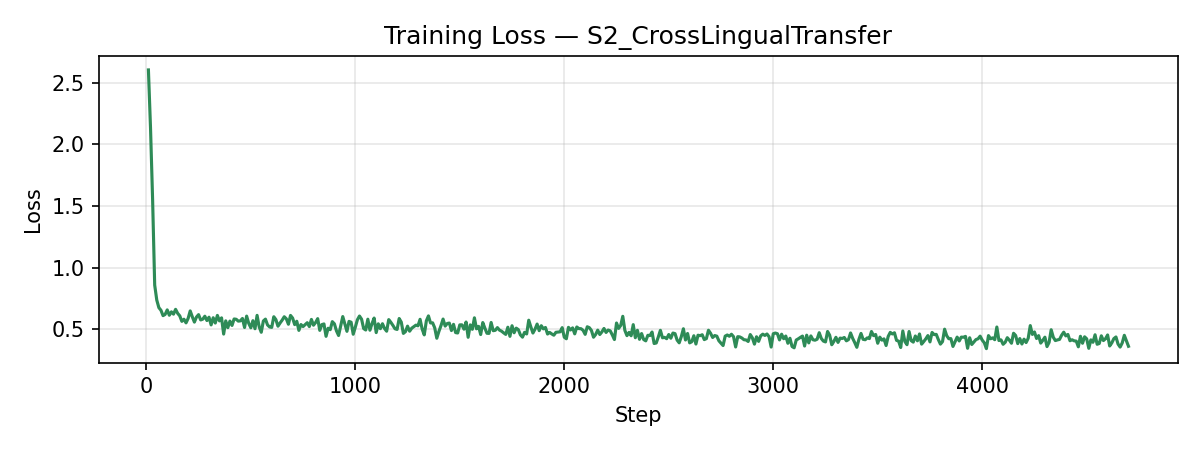

── S3 Back-Translation (v2) ──


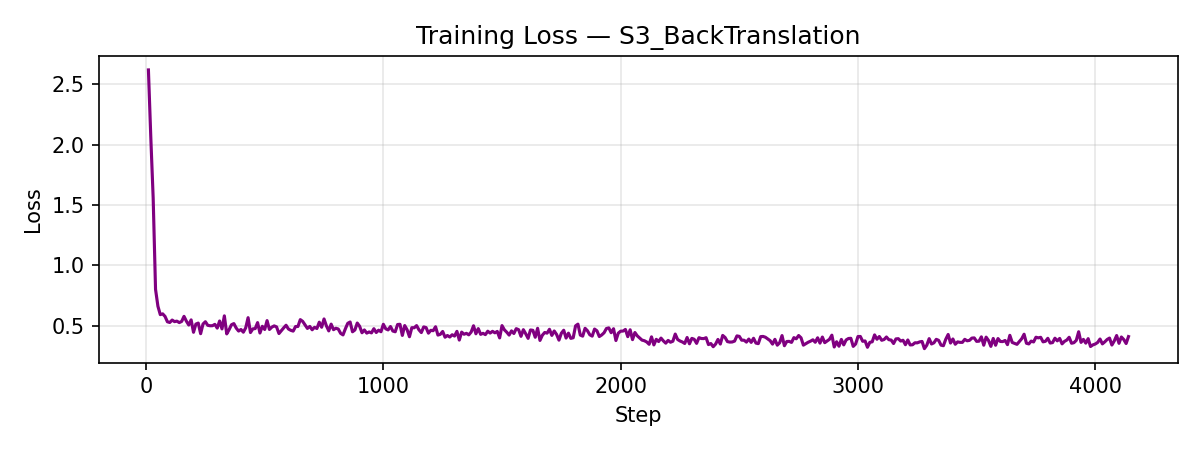

── S4 Agreement Upsamp. ──


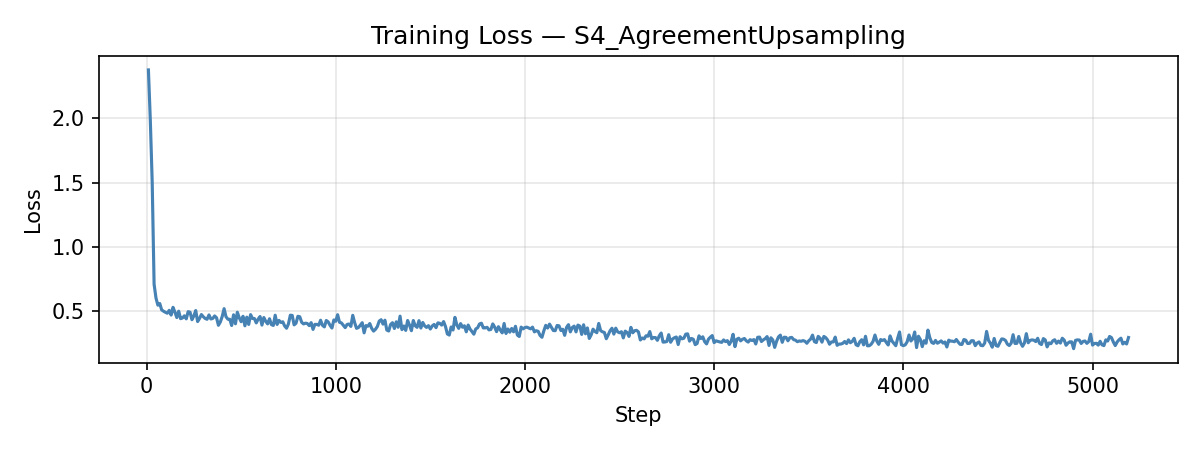

── S5 Multi-LVLM Fusion (v2) ──


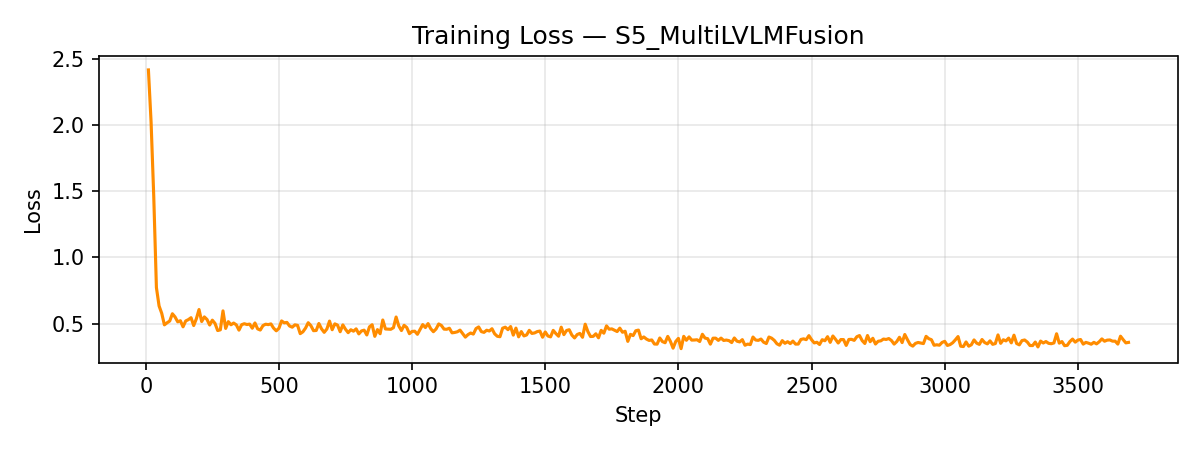

In [10]:
for s, meta in STRATEGIES.items():
    if meta['folder'] is None:
        continue
    img_path = BASE_DIR / meta['folder'] / 'training_loss.png'
    if img_path.exists():
        print(f'── {meta["label"]} ──')
        display(Image(filename=str(img_path), width=600))
    else:
        print(f'[{s}] training_loss.png not found at {img_path}')

---
## 8. Key Findings & Recommendations

### What the numbers say

| Finding | Evidence |
|---|---|
| **S4 (Agreement Upsampling) is the only strategy that beats baseline on ALL three overall metrics** | IoU +0.0176, Spearman +0.0001, CatF1 +0.0235 |
| **All other strategies regress overall** | S1a worst (CatF1 −0.056), then S2, S5, S1b, S3 |
| **EN is consistently hurt** | Every strategy drops EN IoU and Spearman vs baseline |
| **IT and ZH benefit most** | IT CatF1 +0.057 (S4); ZH IoU +0.030 (S4) |
| **OCR is the hardest category** | 4 out of 6 strategies score 0 OCR F1 on at least one language |
| **S4 uniquely boosts OCR F1** | S4 overall OCR F1 = 0.203 vs ≤0.087 for all others |
| **S3 (Back Translation) has the best miscounting F1** | F1(misc) = 0.402 OVERALL |
| **S1a (Heuristic) is the worst augmentation method** | Worst on all metrics; heuristic label quality too low |
| **Mischaracterization F1 is untracked** | Column name collision in `results-compare` cell ('misc'[:4] collision) |

In [11]:
print('=' * 70)
print('QUANTITATIVE SUMMARY')
print('=' * 70)
print(f'{"Strategy":<35} {"IoU":>8} {"Spearman":>10} {"CatF1":>8}')
print('-' * 70)
for s in strat_keys:
    row = dfs[s].loc['OVERALL']
    label = STRATEGIES[s]['label']
    iou = row['Span IoU']
    spe = row['Spearman rho']
    f1  = row['Cat F1 (macro)']
    base = s == 'Baseline'
    suffix = '  ← WINNER' if s == 'S4' else ('  ← baseline' if base else '')
    print(f'{label:<35} {iou:>8.4f} {spe:>10.4f} {f1:>8.4f}{suffix}')

QUANTITATIVE SUMMARY
Strategy                                 IoU   Spearman    CatF1
----------------------------------------------------------------------
Baseline (no synth)                   0.3102     0.3500   0.2861  ← baseline
S1a Heuristic Inj. (v2)               0.2627     0.3018   0.2300
S1b LLM Injection                     0.2755     0.3184   0.2481
S2 Cross-Lingual (v2)                 0.2805     0.3054   0.2435
S3 Back-Translation (v2)              0.2746     0.3056   0.2564
S4 Agreement Upsamp.                  0.3278     0.3501   0.3096  ← WINNER
S5 Multi-LVLM Fusion (v2)             0.2846     0.3172   0.2493


---
## 9. Improvement Recommendations

### Priority 1 — Fix the immediate regressions

**A. Reduce EN synthetic ratio**  
Every strategy hurts EN. The most likely cause: EN synthetic samples introduce distribution mismatch (heuristic or template-generated sentences have different statistical patterns from real VLM output). Fix: either exclude EN from synthetic augmentation entirely, or reduce to 50–100 samples vs 300–2000 currently.

**B. Fix the mischaracterization F1 blind spot**  
In all `results-compare` cells, `cat[:4]` maps both `mischaracterization` and `miscounting` to `'misc'`, so mischaracterization is silently lost. Change to `cat[:8]` or a dict mapping in the results cell of every strategy notebook.

### Priority 2 — Build on S4

**C. Ensemble S4 + S3 (Back Translation)**  
S4 dominates OCR (0.203 vs ≤0.087). S3 dominates miscounting (0.402). They complement each other. Train with S4 samples ∪ S3 samples and see if both advantages stack.

**D. Increase S4 agreement threshold calibration**  
S4 Agreement Upsampling works by reweighting samples where multiple LVLMs agree on hallucinations. Lowering the agreement threshold slightly (if currently strict) could yield more samples while keeping quality high for IT and ZH — the languages that benefit most.

**E. Run S4 with `v2` settings for FR**  
FR is the only language where S4 _didn't_ beat baseline on CatF1 (−0.036). Check whether FR agreement-upsampled samples have lower label diversity.

### Priority 3 — Target OCR

**F. Dedicated OCR augmentation pipeline**  
OCR F1 is near 0 for most strategies. Options:
1. Collect real OCR-error examples from the training set (there are labeled OCR spans already).
2. Use S1b (LLM injection) exclusively for OCR samples — it already achieves 19–28% yield for ZH and ~80% for EN.
3. Mix a small batch of OCR-only synthetic samples (50 per language) into S4 training.

**G. ZH miscounting — complete the S1b run**  
ZH miscounting is currently 0 in S1b due to API balance outage. The improved prompt in the latest fix should fix the inject-fail rate. Once ZH S1b reaches 300 samples, compare ZH CatF1 S1b vs S4.

### Priority 4 — Model / training improvements

**H. Try longer fine-tuning for S4**  
S4 converges with lowest loss and best validation metrics. Try 3 epochs (currently 2) to see if it keeps improving.

**I. Per-language learning rate schedule**  
EN is hurt by augmentation; IT/ZH benefit. Consider using a lower LR for EN-specific batches, or training separate LoRA adapters per language and merging them.

**J. Threshold tuning at inference**  
The model predicts `prob` per span. Calibrate the threshold (currently binary accept/reject at 0.0) per language on validation data — especially for OCR spans which tend to have lower confidence.

---
### Summary: recommended next run order
```
1. S4 + S3 combined training          (should stack OCR + miscounting gains)
2. S4 with EN excluded / reduced      (prevent EN regression)
3. S1b ZH complete (after API topup)  (adds ZH miscounting/other)
4. Fix mischaracterization F1 tracking (baseline comparison fix)
```